# P7. Loop-guard replay

Would a dead-end ledger have stopped the repeated dead ends in the old experience-memory runs (tasks 5 and 16, arms E0 and E1)? This notebook recomputes every number in `quick_runs/results/P7/report.md` from the old run files (read only) and checks it against `summary.json`. Definitions are in `quick_runs/p7/ledger.py` and in the report.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
REPO = Path.cwd().resolve()
while not (REPO / 'quick_runs').is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / 'quick_runs' / 'p7'))
import run as p7
from ledger import replay, coarse_key, outcome_class
rows, examples = [], []
for t in p7.TASKS:
    for a in p7.ARMS:
        r, ex = p7.per_run(t, a)
        rows.append(r); examples += ex
saved = json.loads((REPO / 'quick_runs/results/P7/summary.json').read_text())
assert rows == saved['runs'], 'recomputed numbers differ from summary.json'
print('recomputed numbers match summary.json')

recomputed numbers match summary.json


## Blocked attempts per run (fingerprint key = variables + old design fingerprint)

In [2]:
tab = pd.DataFrame([{k: r[k] for k in ['task', 'arm', 'attempts', 'retries', 'old_dead_end_retries',
      'old_dead_end_retries_check_old_notebook_count', 'old_dead_end_retries_blocked', 'blocked',
      'blocked_that_were_dead_again', 'blocked_that_were_supported', 'attempts_without_fingerprint']} for r in rows])
tab['blocked_share_of_retries'] = (tab.blocked / tab.retries).round(2)
tab

,task,arm,attempts,retries,old_dead_end_retries,old_dead_end_retries_check_old_notebook_count,old_dead_end_retries_blocked,blocked,blocked_that_were_dead_again,blocked_that_were_supported,attempts_without_fingerprint,blocked_share_of_retries
0,5,e0,150,109,4,4,4,14,1,12,0,0.13
1,5,e1,150,92,21,21,21,44,14,29,2,0.48
2,16,e0,150,130,4,4,4,32,0,32,0,0.25
3,16,e1,150,79,30,30,25,47,17,30,18,0.59


## Outcome classes per run

In [3]:
pd.DataFrame([{'task': r['task'], 'arm': r['arm'], **r['outcome_classes'], 'null_flags': r['null_flags'], 'null_flags_also_rejected': r['null_flags_also_rejected']} for r in rows]).fillna(0)

,task,arm,rejected,supported,inconclusive,null_flags,null_flags_also_rejected
0,5,e0,14,134,2.0,11,11
1,5,e1,46,96,8.0,22,22
2,16,e0,6,144,0.0,0,0
3,16,e1,43,107,0.0,8,8


## Coarser key (variables, model family, controls)

In [4]:
pd.DataFrame([{'task': r['task'], 'arm': r['arm'], **r['coarse_key']} for r in rows])

,task,arm,retries,blocked,blocked_that_were_dead_again,blocked_that_were_supported
0,5,e0,127,56,3,52
1,5,e1,127,101,28,67
2,16,e0,138,90,2,88
3,16,e1,136,115,35,80


## Near-duplicates of dead attempts that the fingerprint ledger lets through

In [5]:
pd.DataFrame([{'task': r['task'], 'arm': r['arm'], **r['missed_near_duplicates'],
               'ended_dead_again': sum(r['missed_near_duplicates_dead_again'].values())} for r in rows]).fillna(0)

,task,arm,one_element_off,ended_dead_again,no_design_recorded,same_design_other_wording
0,5,e0,27,1,0.0,0.0
1,5,e1,61,13,2.0,0.0
2,16,e0,27,1,0.0,0.0
3,16,e1,14,14,18.0,24.0


In [6]:
pd.set_option('display.max_colwidth', 200)
pd.DataFrame([{'task': e['task'], 'arm': e['arm'], 'kind': e['kind'],
               'earlier': f"#{e['earlier']['attempt']} {e['earlier']['outcome']}: {e['earlier']['design']}",
               'later': f"#{e['later']['attempt']} {e['later']['outcome']}: {e['later']['design']}"} for e in examples])

,task,arm,kind,earlier,later
0,5,e0,one_element_off,"#0 rejected: logit; controls=['INCOME', 'GENDER', 'BLACK', 'HISPANIC']; moderators=[]; transforms=['AGE_2']; scope='all respondents'","#1 supported: logit; controls=['GENDER', 'BLACK', 'HISPANIC']; moderators=['INCOME']; transforms=['AGE_2']; scope='all respondents'"
1,5,e0,one_element_off,"#0 rejected: logit; controls=['INCOME', 'GENDER', 'BLACK', 'HISPANIC']; moderators=[]; transforms=['AGE_2']; scope='all respondents'","#4 supported: logit; controls=['GENDER', 'BLACK', 'HISPANIC']; moderators=['INCOME']; transforms=['AGE_2']; scope='all respondents'"
2,5,e1,no_design_recorded,"#0 rejected: logit; controls=['INCOME', 'GENDER', 'BLACK', 'HISPANIC']; moderators=[]; transforms=['AGE_2']; scope='all respondents'",#54 inconclusive: -; controls=[]; moderators=[]; transforms=[]; scope='-'
3,5,e1,no_design_recorded,"#55 rejected: logit; controls=['LOG_INCOME', 'GENDER']; moderators=[]; transforms=[]; scope='all respondents'",#69 inconclusive: -; controls=[]; moderators=[]; transforms=[]; scope='-'
4,5,e1,one_element_off,"#1 rejected: logit; controls=['GENDER', 'BLACK', 'HISPANIC']; moderators=['INCOME']; transforms=['log(INCOME)']; scope='all respondents'","#6 rejected: logit; controls=['BLACK', 'HISPANIC']; moderators=['INCOME']; transforms=['log(INCOME)']; scope='all respondents'"
5,5,e1,one_element_off,"#1 rejected: logit; controls=['GENDER', 'BLACK', 'HISPANIC']; moderators=['INCOME']; transforms=['log(INCOME)']; scope='all respondents'","#11 supported: logit; controls=['GENDER', 'BLACK', 'HISPANIC']; moderators=['SAMESAVE', 'INCOME']; transforms=['log(INCOME)']; scope='all respondents'"
6,16,e0,one_element_off,"#10 rejected: ols; controls=['bio1', 'bio12', 'sgr']; moderators=['area']; transforms=[]; scope='all species in the dataset'","#18 supported: ols; controls=['bio1', 'bio12', 'sgr']; moderators=[]; transforms=[]; scope='all rows in the dataset'"
7,16,e0,one_element_off,"#10 rejected: ols; controls=['bio1', 'bio12', 'sgr']; moderators=['area']; transforms=[]; scope='all species in the dataset'","#19 supported: ols; controls=['bio1', 'bio12', 'sgr', 'area']; moderators=[]; transforms=[]; scope='all species in the dataset'"
8,16,e1,same_design_other_wording,#30 rejected: ols; controls=[]; moderators=[]; transforms=[]; scope='all species in the dataset',#32 supported: ols; controls=[]; moderators=[]; transforms=[]; scope='all rows in the dataset'
9,16,e1,same_design_other_wording,#30 rejected: ols; controls=[]; moderators=[]; transforms=[]; scope='all species in the dataset',#36 supported: ols; controls=[]; moderators=[]; transforms=[]; scope='all rows in the dataset'


## When do blocked attempts happen? (cumulative count over the run, E1)

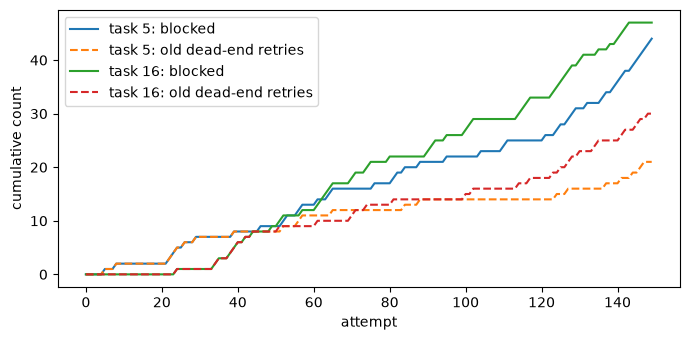

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
for t in p7.TASKS:
    rep = replay(p7.load(t, 'e1'))
    ax.plot(pd.Series([x['blocked'] for x in rep]).cumsum().values, label=f'task {t}: blocked')
    ax.plot(pd.Series([x['old_dead_end_retry'] for x in rep]).cumsum().values, '--', label=f'task {t}: old dead-end retries')
ax.set_xlabel('attempt'); ax.set_ylabel('cumulative count'); ax.legend(); plt.tight_layout()